In [1]:
import pickle

In [2]:
import pandas as pd
df_LP = pd.read_pickle("data/LPdata.pkl")
df_LT = pd.read_pickle("data/LTdata.pkl")
df_binance = pd.read_pickle("data/BinanceData.pkl")

df_LT = df_LT.set_index('timestamp')

In [3]:
LT_buys = df_LT[df_LT.amount0>0]
LT_sells = df_LT[df_LT.amount0<0]

In [4]:
Dtime = '10Min'

In [5]:
prices_binance = df_binance['price'].resample(Dtime).mean()
buy_activity = LT_buys['amount0'].resample(Dtime).sum()   #.rolling(10).mean()
sell_activity = LT_sells['amount0'].resample(Dtime).sum()
pool_price = df_LT['poolPricePrev'].resample(Dtime).mean()

In [6]:
from datetime import datetime as date
d1 = date.fromisoformat('2022-01-01')
d2 = date.fromisoformat('2022-04-30')

In [7]:
def crop_dates(df, d1, d2):
    df = df[df.index >=d1]
    return df[df.index <=d2]

In [8]:
prices_binance = crop_dates(prices_binance, d1,d2)
buy_activity = crop_dates(buy_activity, d1,d2)
sell_activity = crop_dates(sell_activity, d1,d2)
pool_price = crop_dates(pool_price, d1,d2)

In [9]:
df = pd.DataFrame(prices_binance).join(pd.DataFrame(sell_activity).rename(columns= {'amount0':'sells'})).join(pd.DataFrame(buy_activity).rename(columns= {'amount0':'buys'})).join(pool_price)

In [10]:
df = df.rename(columns= {'price':'Binance', 'poolPricePrev':'Uniswap'})

In [11]:
import matplotlib.pyplot as plt
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (15, 5),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"
resolution_value = 300
import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')

In [12]:
df['Difference'] = df.Binance - df.Uniswap

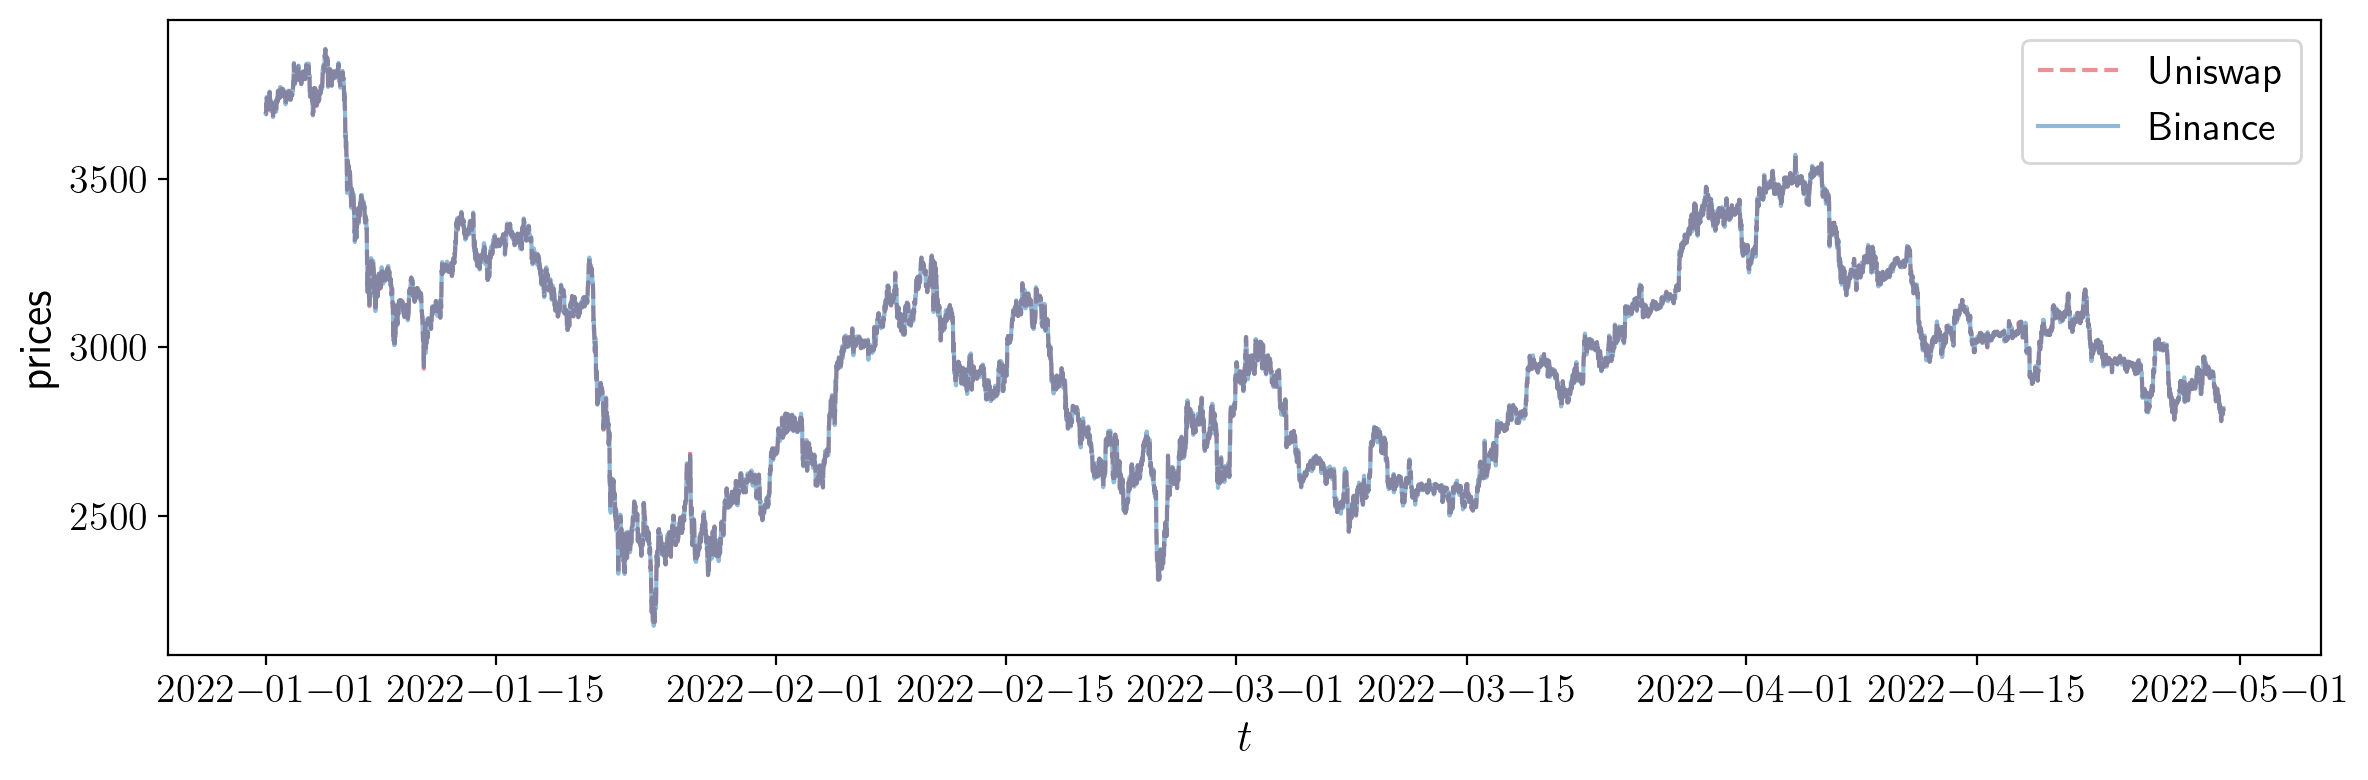

In [13]:
fig, ax = plt.subplots(1,1,figsize=(12,4))
ax.plot(df.index, df.Uniswap, color = 'tab:red', linestyle= '--', label='Uniswap', alpha = 0.5)
ax.plot(df.index, df.Binance, color = 'tab:blue', linestyle= '-', label='Binance',alpha = 0.5)
ax.set_ylabel(r'prices', fontsize = 16)
ax.set_xlabel(r'$t$', fontsize = 16)
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
import statsmodels.api as sm
import numpy as np

In [15]:
df.replace([np.inf,-np.inf], np.nan, inplace = True)

/var/folders/4m/wddbp9t11250z6q39gj69l3w0000gq/T/ipykernel_51985/1655950935.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace([np.inf,-np.inf], np.nan, inplace = True)


In [16]:
df = df.dropna()

In [17]:
mod_buys = sm.OLS(np.asarray(df.buys), sm.add_constant(np.asarray(df.Difference), prepend=False))
res_buys = mod_buys.fit()
print(res_buys.summary())

mod_sells = sm.OLS(np.asarray(-1.*df.sells), sm.add_constant(np.asarray(-1.*df.Difference), prepend=False))
res_sells = mod_sells.fit()
print(res_sells.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.036
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                     633.3
Date:                Sat, 07 Dec 2024   Prob (F-statistic):          3.01e-137
Time:                        10:38:13   Log-Likelihood:            -2.7841e+05
No. Observations:               17131   AIC:                         5.568e+05
Df Residuals:                   17129   BIC:                         5.568e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1          2.322e+05   9228.876     25.165      0.0

In [18]:
sigma = df.Binance.rolling(60*24).std().mean()

In [19]:
x_buys = - res_buys.params[1]/res_buys.params[0] 
x_sells =  res_sells.params[1]/res_sells.params[0] 

In [20]:
import seaborn as sns

/Applications/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


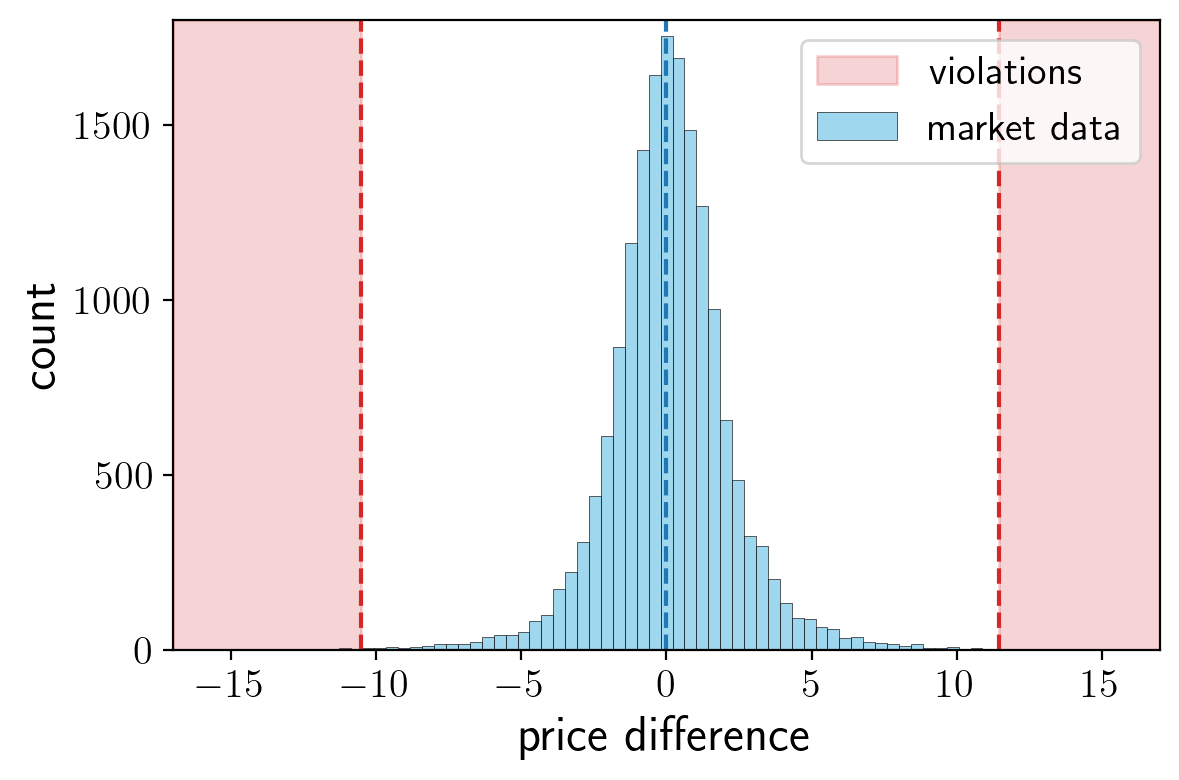

In [29]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

sns.histplot(data=df.Difference, bins = 140, kde=False, color="skyblue", label = 'market data', ax=axs, alpha =0.8)
axs.set_xlabel('price difference', fontsize = 18)
axs.set_ylabel('count', fontsize = 18)

axs.axvline(0,linestyle = '--', color='tab:blue')
axs.axvline(x_buys,linestyle = '--', color='tab:red')
axs.axvline(x_sells,linestyle = '--', color='tab:red')

xmin = -17
xmax = 17
ymax = 1800

xaux_left = np.linspace(xmin, x_buys, 100)
xaux_right = np.linspace(x_sells, xmax, 100)

axs.fill_between(xaux_left, ymax*np.ones_like(xaux_left), color = 'tab:red' , alpha=0.2, label= 'violations')
axs.fill_between(xaux_right, ymax*np.ones_like(xaux_right), color = 'tab:red' , alpha=0.2)

plt.ylim([0,ymax])
plt.tight_layout()
plt.xlim([xmin,xmax])
plt.legend()

plt.tight_layout()
plt.savefig('figures/negative-intensity-regions.pdf', format="pdf", dpi=resolution_value)
plt.show()